# 01. SECOM EDA — 결측, 상수 피처, 클래스 불균형

**목표**: 모델링 전에 데이터가 가진 "함정"을 찾아내고, 전처리·분할·평가 방식을 **근거 있게** 결정한다.

SECOM: 반도체 제조 공정의 센서 590개 × 1567 생산 단위, 라벨은 공정 내 테스트 Pass/Fail.
센서 이름이 익명화되어 있어 도메인 지식 대신 **데이터 자체의 통계적 성질**로 판단해야 한다.

확인할 질문:
1. 불량은 얼마나 드문가? → 평가 지표 선택
2. 결측은 얼마나, 어떤 패턴으로 있나? → 제거 vs 대체, 결측 자체가 신호인가?
3. 정보가 없는 센서(상수·준상수)는 몇 개인가?
4. 시간에 따라 분포가 변하나? → train/test 분할 방식
5. 중복(고상관) 센서는 얼마나 되나? → 해석(SHAP) 시 주의점

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

df = pd.read_parquet(ROOT / "data" / "processed" / "secom.parquet")
X = df.filter(like="sensor_")
y = df["fail"]
print(f"rows={len(df)}, sensors={X.shape[1]}")
df.iloc[:5, :8]

rows=1567, sensors=590


,timestamp,fail,sensor_000,sensor_001,sensor_002,sensor_003,sensor_004,sensor_005
0,2008-07-19 11:55:00,0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0
1,2008-07-19 12:32:00,0,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0
2,2008-07-19 13:17:00,1,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0
3,2008-07-19 14:43:00,0,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0
4,2008-07-19 15:22:00,0,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0


## 1. 클래스 비율

fail
pass    1463
fail     104
fail rate = 6.64%  (pass:fail ≈ 14.1:1)
'모두 pass'로 찍는 모델의 정확도 = 93.36%


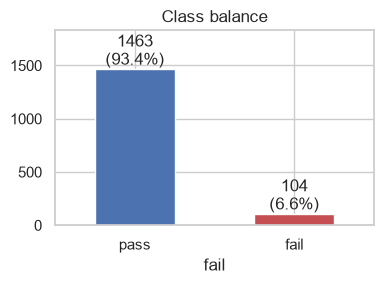

In [2]:
counts = y.value_counts().rename({0: "pass", 1: "fail"})
ratio = counts["pass"] / counts["fail"]
print(counts.to_string())
print(f"fail rate = {y.mean():.2%}  (pass:fail ≈ {ratio:.1f}:1)")
print(f"'모두 pass'로 찍는 모델의 정확도 = {1 - y.mean():.2%}")

fig, ax = plt.subplots(figsize=(4, 3))
counts.plot.bar(ax=ax, color=["#4C72B0", "#C44E52"], rot=0)
for i, v in enumerate(counts):
    ax.text(i, v, f"{v}\n({v / len(y):.1%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.25)
ax.set_title("Class balance")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_class_balance.png", dpi=150)

**해석**: 불량은 6.6% (약 14:1). 아무것도 학습하지 않고 전부 pass로 찍어도 정확도 93.4%가 나온다.
→ **정확도는 주 지표로 쓸 수 없다.** 주 지표는
- **PR-AUC (Average Precision)**: 양성(불량)이 드물 때 ROC-AUC보다 모델 간 차이를 정직하게 보여준다.
  ROC-AUC는 TN이 압도적으로 많으면 FPR이 작게 나와 낙관적으로 보이기 쉽다.
  PR-AUC의 무작위 기준선 = 양성 비율(≈0.066)이라는 것도 기억할 것.
- **불량 재현율(Recall)**: 제조에서는 불량을 놓치는 비용(후공정 투입, 고객 불량)이 오검출(재검사) 비용보다 크다.
- 학습 시에는 `class_weight`로 소수 클래스 손실에 가중치를 준다.

## 2. 결측 분석

In [3]:
miss = X.isna().mean().sort_values(ascending=False)
print(f"전체 셀 결측률: {X.isna().values.mean():.2%}")
print(f"결측 있는 센서: {(miss > 0).sum()} / {X.shape[1]}")
summary = pd.Series({f"> {int(t*100)}%": int((miss > t).sum()) for t in [0.05, 0.2, 0.5, 0.8]},
                    name="센서 수")
summary.to_frame()

전체 셀 결측률: 4.54%
결측 있는 센서: 538 / 590


,센서 수
> 5%,52
> 20%,32
> 50%,28
> 80%,8


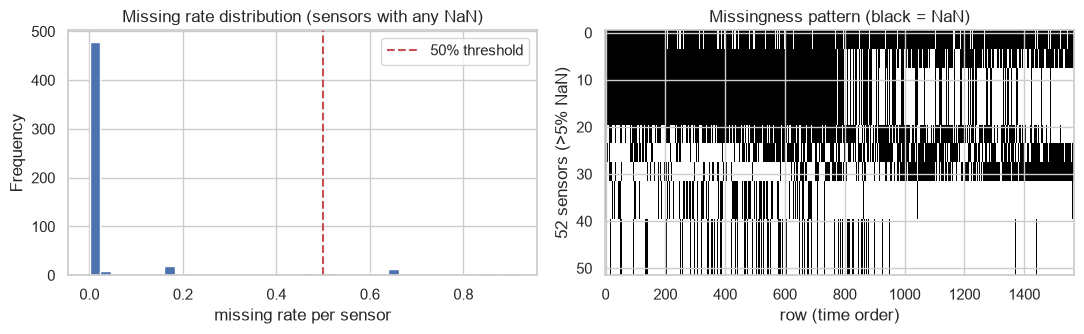

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
miss[miss > 0].plot.hist(bins=40, ax=axes[0], color="#4C72B0")
axes[0].axvline(0.5, color="r", ls="--", label="50% threshold")
axes[0].set_xlabel("missing rate per sensor"); axes[0].set_title("Missing rate distribution (sensors with any NaN)")
axes[0].legend()

# 결측 패턴: 같은 행들에서 함께 빠지는 센서 블록이 있는지 확인
top = miss.index[miss > 0.05]
axes[1].imshow(X[top].isna().T.values, aspect="auto", cmap="Greys", interpolation="nearest")
axes[1].set_xlabel("row (time order)"); axes[1].set_ylabel(f"{len(top)} sensors (>5% NaN)")
axes[1].set_title("Missingness pattern (black = NaN)")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_missing.png", dpi=150)

**해석**
- 결측은 대부분 낮지만, **소수 센서가 극단적으로 비어 있다** (50% 초과 28개, 80% 초과 8개).
- 오른쪽 그림에서 여러 센서가 **같은 행 구간에서 동시에** 비어 있다 → 무작위 결측이 아니라
  특정 기간/장비 상태에서 계측이 꺼진 "블록 결측"일 가능성이 높다.

그럼 **결측 자체가 불량과 관련이 있을까?** 결측 여부(0/1)와 불량의 연관성을 Fisher 정확 검정으로 확인한다.

In [5]:
from scipy.stats import fisher_exact

rows = []
for c in miss.index[(miss > 0.01) & (miss < 0.99)]:
    is_na = X[c].isna()
    _, p = fisher_exact(pd.crosstab(is_na, y))
    rows.append({"sensor": c, "missing_rate": miss[c], "p_value": p,
                 "fail_rate_if_missing": y[is_na].mean(), "fail_rate_if_present": y[~is_na].mean()})
na_assoc = pd.DataFrame(rows).sort_values("p_value")
print(f"결측 여부가 불량과 유의하게 연관된 센서 (p<0.01): {(na_assoc.p_value < 0.01).sum()}개")
na_assoc.head(8).round(4)

결측 여부가 불량과 유의하게 연관된 센서 (p<0.01): 8개


,sensor,missing_rate,p_value,fail_rate_if_missing,fail_rate_if_present
27,sensor_345,0.5067,0.0008,0.0453,0.0880
26,sensor_072,0.5067,0.0008,0.0453,0.0880
25,sensor_073,0.5067,0.0008,0.0453,0.0880
24,sensor_346,0.5067,0.0008,0.0453,0.0880
31,sensor_519,0.4563,0.0031,0.0462,0.0833
30,sensor_385,0.4563,0.0031,0.0462,0.0833
28,sensor_112,0.4563,0.0031,0.0462,0.0833
29,sensor_247,0.4563,0.0031,0.0462,0.0833


**해석**: 50% 가까이 빠진 센서 몇 개는 "**값이 있을 때** 불량률 ≈ 8.8%, **없을 때** ≈ 4.5%"로 차이가 유의하다.
결측이 단순 노이즈가 아니라 **공정 조건(어떤 레시피/장비를 탔는지)을 간접적으로 알려주는 신호**일 수 있다.

하지만 바로 믿으면 안 된다. 위 결측 패턴 그림에서 **행 ~780 전후로 결측 양상이 확 바뀐다** → 결측이 "시간(시기)"의 대리변수일 수 있다.

In [6]:
half = len(df) // 2
check = pd.DataFrame({
    "1st half": [X["sensor_072"].isna()[:half].mean(), X["sensor_112"].isna()[:half].mean(), y[:half].mean()],
    "2nd half": [X["sensor_072"].isna()[half:].mean(), X["sensor_112"].isna()[half:].mean(), y[half:].mean()],
}, index=["sensor_072 missing rate", "sensor_112 missing rate", "fail rate"])
check.style.format("{:.1%}")

,1st half,2nd half
sensor_072 missing rate,37.8%,63.5%
sensor_112 missing rate,24.0%,67.2%
fail rate,8.6%,4.7%


**해석 (교란 변수 확인)**: 후반부로 갈수록 이 센서들의 결측은 **늘고**, 불량률은 **줄었다**.
따라서 "결측이면 불량이 적다"는 관계는 센서 자체보다 **시기(공정 개선 이후)라는 교란 변수** 때문일 가능성이 크다.
시간순 분할에서는 이런 피처가 train에서 학습한 관계가 test에서 그대로 유지되지 않을 수 있다.

→ 전처리 결정:
- 결측률이 매우 높은 센서는 값 자체는 제거하되, **결측 지시자(missing indicator)를 남기는 옵션**을 실험한다.
- 나머지는 **중앙값 대체** (센서 값은 이상치·치우침이 있어 평균보다 중앙값이 안전).
- 임계값과 중앙값은 반드시 **train에서만 계산** (test 정보 누수 방지 → sklearn Pipeline으로 강제).

## 3. 상수 / 준상수 피처

In [7]:
nunique = X.nunique(dropna=True)
const_cols = nunique.index[nunique <= 1]
binary_cols = nunique.index[nunique == 2]
print(f"상수 센서 (값이 1종류): {len(const_cols)}개")
print(f"값이 2종류뿐인 센서:   {len(binary_cols)}개")

# 준상수: 최빈값이 95% 이상을 차지하는 센서
top_freq = X.apply(lambda s: s.value_counts(normalize=True, dropna=True).iloc[0] if s.notna().any() else 1.0)
near_const = top_freq.index[(top_freq >= 0.95) & (nunique > 1)]
print(f"준상수 센서 (최빈값 비중 ≥95%): {len(near_const)}개")

상수 센서 (값이 1종류): 116개
값이 2종류뿐인 센서:   6개


준상수 센서 (최빈값 비중 ≥95%): 10개


**해석**: 590개 중 **116개(약 20%)가 완전 상수** — 분산이 0이라 어떤 모델에도 정보가 없다.
아마 해당 계측 항목이 이 제품/기간에는 고정 설정값이었던 것으로 보인다.
→ 제거해도 손실 0, 모델·SHAP 계산을 가볍게 만든다. (sklearn `VarianceThreshold`로 Pipeline 안에서 처리)

준상수는 **바로 지우지 않는다**: 드문 값이 정확히 불량과 연결될 수도 있기 때문. 트리 모델은 이런 피처를 스스로 무시할 수 있다.

## 4. 시간에 따른 변화 (분할 방식 결정)

기간: 2008-07-19 11:55:00 ~ 2008-10-17 06:07:00,  시간순 정렬 여부: True


,n,fail_rate
timestamp,,
2008-07-01 00:00:00,63,22.2%
2008-08-01 00:00:00,555,9.2%
2008-09-01 00:00:00,590,2.9%
2008-10-01 00:00:00,359,6.1%


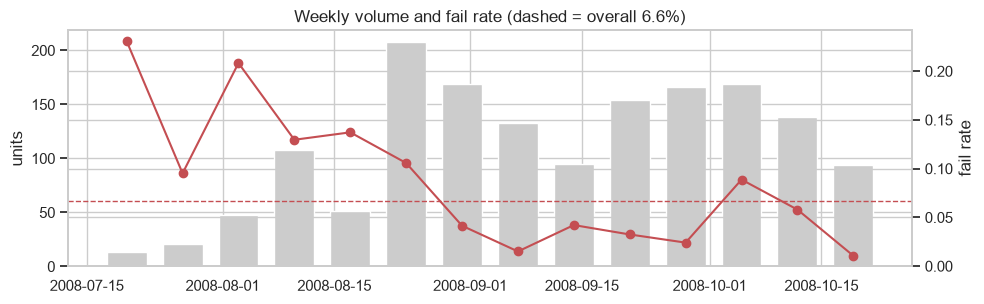

In [8]:
print(f"기간: {df.timestamp.min()} ~ {df.timestamp.max()},  시간순 정렬 여부: {df.timestamp.is_monotonic_increasing}")
monthly = df.set_index("timestamp")["fail"].resample("MS").agg(["count", "mean"])
monthly.columns = ["n", "fail_rate"]
display(monthly.style.format({"fail_rate": "{:.1%}"}))

weekly = df.set_index("timestamp")["fail"].resample("W").agg(["count", "mean"])
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(weekly.index, weekly["count"], width=5, color="#CCCCCC", label="units / week")
ax2 = ax.twinx()
ax2.plot(weekly.index, weekly["mean"], "o-", color="#C44E52", label="fail rate")
ax2.axhline(y.mean(), color="#C44E52", ls="--", lw=1)
ax.set_ylabel("units"); ax2.set_ylabel("fail rate")
ax.set_title("Weekly volume and fail rate (dashed = overall 6.6%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_fail_rate_over_time.png", dpi=150)

**해석**: 불량률이 **7월 22% → 9월 2.9%**로 크게 움직인다. 공정 개선, 레시피 변경 등으로 분포가 바뀌는(drift) 전형적인 제조 데이터다.

→ 분할 결정: **시간순 분할** (앞 ~75% 학습, 뒤 ~25% 테스트)
- 무작위 분할은 "미래 데이터로 과거를 맞히는" 셈이 되어 성능을 과대평가한다.
- 실제 배포 상황은 "과거로 학습 → 앞으로 생산될 웨이퍼 예측"이므로 시간순 분할이 현실과 같다.
- 단, 테스트 구간의 불량률이 train과 다르다는 점은 결과 해석 시 반드시 언급한다.
- 비교용으로 계층적(stratified) 무작위 분할 결과도 함께 보고하면 drift의 영향을 보여줄 수 있다.

## 5. 고상관(중복) 센서

|r| > 0.95 인 센서 쌍: 329개,  다른 센서와 거의 중복인 센서: 194개


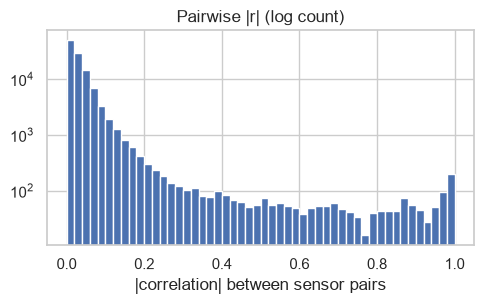

In [9]:
Xv = X.drop(columns=const_cols)
corr = Xv.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
high_pairs = (upper > 0.95).sum().sum()
redundant = (upper > 0.95).any(axis=0).sum()
print(f"|r| > 0.95 인 센서 쌍: {high_pairs}개,  다른 센서와 거의 중복인 센서: {redundant}개")

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.hist(upper.stack().values, bins=50, color="#4C72B0")
ax.set_yscale("log"); ax.set_xlabel("|correlation| between sensor pairs"); ax.set_title("Pairwise |r| (log count)")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_correlation.png", dpi=150)

**해석**: 상수 제거 후에도 **194개 센서가 다른 센서와 |r|>0.95**로 사실상 중복이다 (같은 물리량을 여러 위치/단위로 측정한 것으로 추정).
- 로지스틱 회귀: 다중공선성 → 계수가 불안정 → **L2 규제 + 표준화**로 대응.
- LightGBM: 성능에는 큰 문제 없지만, **SHAP 중요도가 중복 센서들 사이에 나뉘어** 하나하나가 덜 중요해 보일 수 있다.
  → 해석 단계에서 "이 센서와 상관이 높은 그룹"을 같이 보고하는 것이 정확하다.

## 6. EDA 요약 → 다음 단계 설계

| 발견 | 수치 | 결정 |
|---|---|---|
| 클래스 불균형 | fail 6.6% (14:1) | 주 지표 PR-AUC·불량 재현율, `class_weight` 사용, 정확도는 보조 |
| 고결측 센서 | >50%: 28개, >80%: 8개 | 고결측 열 제거 (임계값은 train 기준), 나머지 중앙값 대체 |
| 결측이 신호? | 블록 결측, 8개 센서는 불량률과 유의하게 연관 — 단 시기와 교란 | 결측 지시자는 on/off 비교 실험, 시간순 test로 검증 |
| 상수 센서 | 116개 | `VarianceThreshold`로 제거 |
| 시간 drift | 월별 불량률 2.9%~22% | **시간순 분할**, 랜덤 분할과 비교 |
| 중복 센서 | 194개가 |r|>0.95 | 로지스틱은 표준화+L2, SHAP는 상관 그룹 함께 해석 |

모든 "train에서 계산하는 값"(결측 임계, 중앙값, 스케일러)은 **Pipeline 내부**에서 fit → test 누수 차단.